# QA search in binary latent space

Visualize initial and QA-sampled binary vectors for AAV capsid surface region variants in two dimensions using UMAP.

In [1]:
# Visualize the QA search in binary latent space using UMAP for AAV capsid variants.
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

## Load sampled binary vectors

In [2]:
# Load the data.
plm_res = "...\\pLM-bVAE\\reproduction_paper\\outputs\\"
# bvae
bvae_all_sample1 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa1\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample2 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa2\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample3 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa3\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample4 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa4\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample5 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa5\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample6 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa6\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample7 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa7\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample8 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa8\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample9 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa9\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
bvae_all_sample10 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa10\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])

# Load the sequences.
# bvae decoded_list
bvae_decoded1 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa1\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded2 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa2\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded3 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa3\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded4 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa4\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded5 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa5\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded6 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa6\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded7 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa7\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded8 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa8\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded9 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa9\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
bvae_decoded10 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa10\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])

# Load binary vectors.
# bvae binary vectors
bvae_binary1 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa1\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
bvae_binary2 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa2\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
bvae_binary3 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa3\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
bvae_binary4 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa4\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
bvae_binary5 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa5\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
bvae_binary6 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa6\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
bvae_binary7 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa7\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
bvae_binary8 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa8\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
bvae_binary9 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa9\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
bvae_binary10 = pd.read_csv(plm_res +'moqa\\aav\\bvae_moqa10\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})

# Merge decoded sequences, binary vectors, and sampled data.
bvae_all_sample1 = pd.concat([bvae_decoded1, bvae_binary1, bvae_all_sample1], axis=1)
bvae_all_sample2 = pd.concat([bvae_decoded2, bvae_binary2, bvae_all_sample2], axis=1)
bvae_all_sample3 = pd.concat([bvae_decoded3, bvae_binary3, bvae_all_sample3], axis=1)
bvae_all_sample4 = pd.concat([bvae_decoded4, bvae_binary4, bvae_all_sample4], axis=1)
bvae_all_sample5 = pd.concat([bvae_decoded5, bvae_binary5, bvae_all_sample5], axis=1)
bvae_all_sample6 = pd.concat([bvae_decoded6, bvae_binary6, bvae_all_sample6], axis=1)
bvae_all_sample7 = pd.concat([bvae_decoded7, bvae_binary7, bvae_all_sample7], axis=1)
bvae_all_sample8 = pd.concat([bvae_decoded8, bvae_binary8, bvae_all_sample8], axis=1)
bvae_all_sample9 = pd.concat([bvae_decoded9, bvae_binary9, bvae_all_sample9], axis=1)
bvae_all_sample10 = pd.concat([bvae_decoded10, bvae_binary10, bvae_all_sample10], axis=1)

# Combine the ten bVAE runs.
bvae_all_samples = pd.concat([bvae_all_sample1, bvae_all_sample2, bvae_all_sample3, bvae_all_sample4, bvae_all_sample5, bvae_all_sample6, bvae_all_sample7, bvae_all_sample8, bvae_all_sample9, bvae_all_sample10], ignore_index=True)

# Remove whitespace from each amino acid sequence.
bvae_all_samples['seq'] = bvae_all_samples['seq'].str.replace(' ', '')

# Average the three predictor scores in bb_score_avg.
bvae_all_samples['bb_score_avg'] = bvae_all_samples[['bb_score1', 'bb_score2', 'bb_score3']].mean(axis=1)

# Convert space-separated bVAE binary vectors to coordinates.
bvae_all_samples['binary_seq_array'] = bvae_all_samples['binary_seq'].apply(lambda x: np.array(x.split()).astype(int))

len(bvae_all_samples)

20000

In [3]:
# esm_650m_opt
esm_650m_opt_all_sample1 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa1\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample2 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa2\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample3 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa3\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample4 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa4\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample5 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa5\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample6 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa6\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample7 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa7\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample8 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa8\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample9 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa9\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])
esm_650m_opt_all_sample10 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa10\\model_output\\binary\\all_points_samples.txt', sep=" ", header=None, names=["iter", "bb_score1", "bb_score2", "bb_score3", "moqa_score", "E_norm_reads", "cbf_reads", "E_reads", "fm_score"])

# Load the sequences.
# esm_650m_opt decoded_list
esm_650m_opt_decoded1 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa1\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded2 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa2\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded3 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa3\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded4 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa4\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded5 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa5\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded6 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa6\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded7 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa7\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded8 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa8\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded9 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa9\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])
esm_650m_opt_decoded10 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa10\\model_output\\binary\\decoded_list.txt', sep="\t", header=None, names=["seq"])

# Load binary vectors.
# esm_650m_opt binary vectors
esm_650m_opt_binary1 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa1\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
esm_650m_opt_binary2 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa2\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
esm_650m_opt_binary3 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa3\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
esm_650m_opt_binary4 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa4\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
esm_650m_opt_binary5 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa5\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
esm_650m_opt_binary6 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa6\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
esm_650m_opt_binary7 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa7\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
esm_650m_opt_binary8 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa8\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
esm_650m_opt_binary9 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa9\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})
esm_650m_opt_binary10 = pd.read_csv(plm_res +'moqa\\aav\\esm_650m_opt_moqa10\\model_output\\binary\\vectors_list.txt', sep="\t", header=None, names=["seq"]).rename(columns={"seq": "binary_seq"})

# Merge decoded sequences with sampled data.
esm_650m_opt_all_sample1 = pd.concat([esm_650m_opt_decoded1, esm_650m_opt_binary1, esm_650m_opt_all_sample1], axis=1)
esm_650m_opt_all_sample2 = pd.concat([esm_650m_opt_decoded2, esm_650m_opt_binary2, esm_650m_opt_all_sample2], axis=1)
esm_650m_opt_all_sample3 = pd.concat([esm_650m_opt_decoded3, esm_650m_opt_binary3, esm_650m_opt_all_sample3], axis=1)
esm_650m_opt_all_sample4 = pd.concat([esm_650m_opt_decoded4, esm_650m_opt_binary4, esm_650m_opt_all_sample4], axis=1)
esm_650m_opt_all_sample5 = pd.concat([esm_650m_opt_decoded5, esm_650m_opt_binary5, esm_650m_opt_all_sample5], axis=1)
esm_650m_opt_all_sample6 = pd.concat([esm_650m_opt_decoded6, esm_650m_opt_binary6, esm_650m_opt_all_sample6], axis=1)
esm_650m_opt_all_sample7 = pd.concat([esm_650m_opt_decoded7, esm_650m_opt_binary7, esm_650m_opt_all_sample7], axis=1)
esm_650m_opt_all_sample8 = pd.concat([esm_650m_opt_decoded8, esm_650m_opt_binary8, esm_650m_opt_all_sample8], axis=1)
esm_650m_opt_all_sample9 = pd.concat([esm_650m_opt_decoded9, esm_650m_opt_binary9, esm_650m_opt_all_sample9], axis=1)
esm_650m_opt_all_sample10 = pd.concat([esm_650m_opt_decoded10, esm_650m_opt_binary10, esm_650m_opt_all_sample10], axis=1)

# Combine the ten pLM-bVAE (HPO) runs.
esm_650m_opt_all_samples = pd.concat([esm_650m_opt_all_sample1, esm_650m_opt_all_sample2, esm_650m_opt_all_sample3, esm_650m_opt_all_sample4, esm_650m_opt_all_sample5, esm_650m_opt_all_sample6, esm_650m_opt_all_sample7, esm_650m_opt_all_sample8, esm_650m_opt_all_sample9, esm_650m_opt_all_sample10], ignore_index=True)

# Remove whitespace from each amino acid sequence.
esm_650m_opt_all_samples['seq'] = esm_650m_opt_all_samples['seq'].str.replace(' ', '')

# Average the three predictor scores in bb_score_avg.
esm_650m_opt_all_samples['bb_score_avg'] = esm_650m_opt_all_samples[['bb_score1', 'bb_score2', 'bb_score3']].mean(axis=1)

# Convert space-separated binary vectors to coordinates.
esm_650m_opt_all_samples['binary_seq_array'] = esm_650m_opt_all_samples['binary_seq'].apply(lambda x: np.array(x.split()).astype(int))

len(esm_650m_opt_all_samples)

19970

## Load initial binary vectors

In [4]:
# Load the initial data.
plm_data = "...\\pLM-bVAE\\reproduction_paper\\data\\"

init_binary1 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_1.txt', sep="\t", header=None, names=["binary_seq"])
init_binary2 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_2.txt', sep="\t", header=None, names=["binary_seq"])
init_binary3 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_3.txt', sep="\t", header=None, names=["binary_seq"])
init_binary4 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_4.txt', sep="\t", header=None, names=["binary_seq"])
init_binary5 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_5.txt', sep="\t", header=None, names=["binary_seq"])
init_binary6 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_6.txt', sep="\t", header=None, names=["binary_seq"])
init_binary7 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_7.txt', sep="\t", header=None, names=["binary_seq"])
init_binary8 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_8.txt', sep="\t", header=None, names=["binary_seq"])
init_binary9 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_9.txt', sep="\t", header=None, names=["binary_seq"])
init_binary10 = pd.read_csv(plm_data + 'moqa_initial_data\\binary_vectors_l64_part_10.txt', sep="\t", header=None, names=["binary_seq"])

# Combine initial data from the ten runs.
init_binary_all = pd.concat([init_binary1, init_binary2, init_binary3, init_binary4, init_binary5, init_binary6, init_binary7, init_binary8, init_binary9, init_binary10], ignore_index=True)

# Convert space-separated initial binary vectors to coordinates.
init_binary_all['binary_seq_array'] = init_binary_all['binary_seq'].apply(lambda x: np.array(x.split()).astype(int))

len(init_binary_all)

20000

## Filter penalized samples

In [5]:
# Count rows with a penalty score of -1e6.
print((bvae_all_samples['bb_score1'] == -1e6).sum())
print((esm_650m_opt_all_samples['bb_score1'] == -1e6).sum())

# Exclude rows with a penalty score of -1e6.
bvae_all_samples_del_penalty = bvae_all_samples[bvae_all_samples['bb_score1'] != -1e6]
esm_650m_opt_all_samples_del_penalty = esm_650m_opt_all_samples[esm_650m_opt_all_samples['bb_score1'] != -1e6]

99
0


## Project binary vectors and visualize the search

In [6]:
# Use UMAP to reduce the binary vectors to two dimensions.
from umap import UMAP
# Convert binary vectors to a two-dimensional NumPy array.
init_binary_array = np.stack(init_binary_all['binary_seq_array'].values)
bvae_binary_array = np.stack(bvae_all_samples_del_penalty['binary_seq_array'].values)
esm_650m_opt_binary_array = np.stack(esm_650m_opt_all_samples_del_penalty['binary_seq_array'].values)
X_all = np.vstack([
    init_binary_array,
    bvae_binary_array,
    esm_650m_opt_binary_array
])

reducer = UMAP(n_components=2,
               n_neighbors=15,
               min_dist=0.1,
               metric='hamming',
               random_state=4)

X_all_umap = reducer.fit_transform(X_all)

init_umap_embedding = X_all_umap[:len(init_binary_array)]
bvae_umap_embedding = X_all_umap[len(init_binary_array):len(init_binary_array) + len(bvae_binary_array)]
esm_650m_opt_umap_embedding = X_all_umap[len(init_binary_array) + len(bvae_binary_array):]

init_binary_all['umap1'] = init_umap_embedding[:, 0]
init_binary_all['umap2'] = init_umap_embedding[:, 1]
bvae_all_samples_del_penalty['umap1'] = bvae_umap_embedding[:, 0]
bvae_all_samples_del_penalty['umap2'] = bvae_umap_embedding[:, 1]
esm_650m_opt_all_samples_del_penalty['umap1'] = esm_650m_opt_umap_embedding[:, 0]
esm_650m_opt_all_samples_del_penalty['umap2'] = esm_650m_opt_umap_embedding[:, 1]

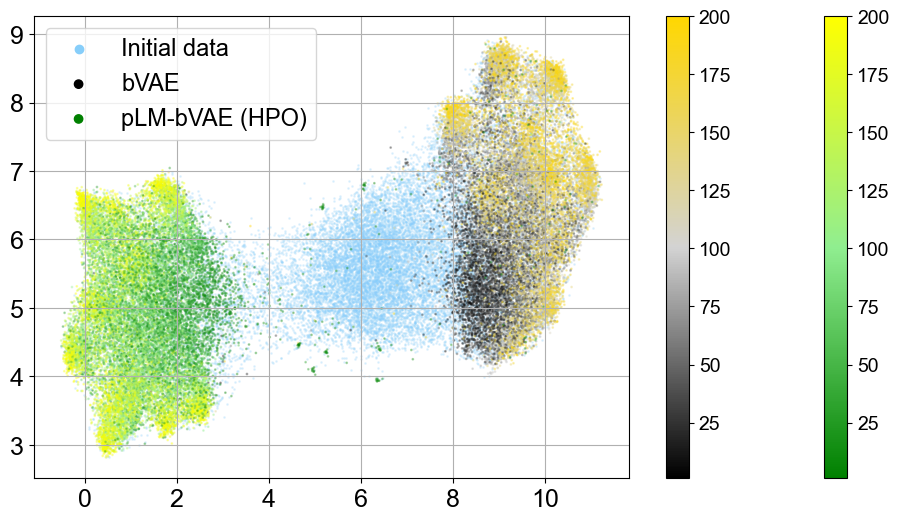

In [7]:
from matplotlib.colors import LinearSegmentedColormap
plt.figure(figsize=(12, 6))

# Define a colormap.
bvae_cmap = LinearSegmentedColormap.from_list(
    "bvae_custom",
    ["black", "lightgray", "gold"]
)

esm_cmap = LinearSegmentedColormap.from_list(
    "esm_custom",
    ["green", "lightgreen", "yellow"]
)

sc1 = plt.scatter(init_binary_all['umap1'], init_binary_all['umap2'],
            s=1, alpha=0.2, label='Initial data',
            c='lightskyblue')

sc2 = plt.scatter(bvae_all_samples_del_penalty['umap1'], bvae_all_samples_del_penalty['umap2'],
            s=1, alpha=0.3, label='bVAE',
            c=bvae_all_samples_del_penalty['iter'],
            cmap=bvae_cmap)

sc3 = plt.scatter(esm_650m_opt_all_samples_del_penalty['umap1'], esm_650m_opt_all_samples_del_penalty['umap2'],
            s=1, alpha=0.3, label='pLM-bVAE (HPO)',
            c=esm_650m_opt_all_samples_del_penalty['iter'],
            cmap=esm_cmap)

cbar_esm = plt.colorbar(sc3)
cbar_bvae = plt.colorbar(sc2)

# cbar_esm.set_label('Iteration (pLM-bVAE (HPO))',
#                    fontsize=16, labelpad=12)
# cbar_bvae.set_label('Iteration (bVAE)',
#                     fontsize=16, labelpad=12)
cbar_esm.ax.tick_params(labelsize=14)
cbar_bvae.ax.tick_params(labelsize=14)

cbar_esm.solids.set_alpha(1.0)
cbar_bvae.solids.set_alpha(1.0)

# plt.xlabel('UMAP1')
# plt.ylabel('UMAP2')
# plt.title('UMAP of binary latent vectors')
plt.xlabel("")
plt.ylabel("")
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

leg = plt.legend(fontsize=17, markerscale=6)
for handle in leg.legend_handles:
    handle.set_alpha(1)

plt.grid(True)
plt.show()